# Q1.Rice leaf diseas detection using NN


In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import matplotlib.image as mpimg
import os
import random
import shutil

from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator


we define a seed set function to avoid the varing output every time


In [ ]:
SEED = 42

def set_seeds(seed=SEED):
    os.environ['PYTHONHASHSEED'] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)
    print(f"fixed the seed: {seed}")

set_seeds()


fixed the seed: 42


## import data set




In [ ]:
import kagglehub
kaggle_cnt_path = kagglehub.dataset_download("anshulm257/rice-disease-dataset")
print ("dataset has been downloaded in this path :", kaggle_cnt_path)


Using Colab cache for faster access to the 'rice-disease-dataset' dataset.
dataset has been downloaded in this path : /kaggle/input/rice-disease-dataset


## see if the data has been loaded successfuly and the content are whole




folder content:
['Rice_Leaf_AUG']
the categories inside Rice_Leaf_AUG :['Leaf scald', 'Sheath Blight', 'Healthy Rice Leaf', 'Leaf Blast', 'Brown Spot', 'Bacterial Leaf Blight'] 


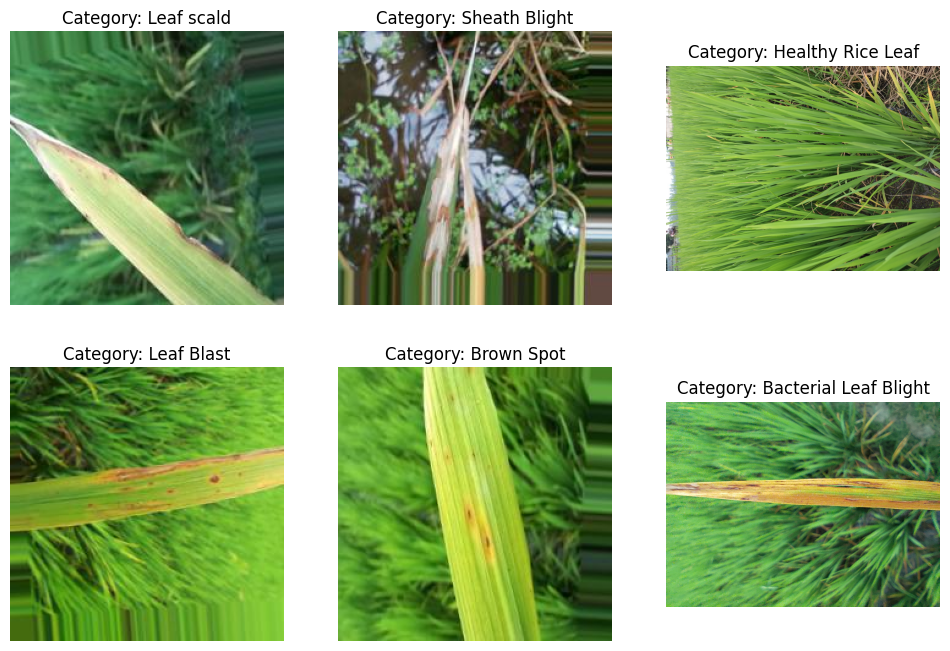

In [ ]:
print("folder content:")
print (os.listdir(kaggle_cnt_path))

Rice_Leaf_AUG_path=os.path.join(kaggle_cnt_path,'Rice_Leaf_AUG')
#folder content:['Rice_Leaf_AUG']
categories=os.listdir(Rice_Leaf_AUG_path)
print(f"the categories inside Rice_Leaf_AUG :{categories} ")

plt.figure(figsize=(12,8))

for i,cat_name in enumerate (categories):

  cat_folder=os.path.join(Rice_Leaf_AUG_path,cat_name)
  cat_images=os.listdir(cat_folder)

  if len(cat_images)>0:
    random_image=random.choice(cat_images)
    image_path=os.path.join(cat_folder,random_image)
    img=mpimg.imread(image_path)
    plt.subplot(2,3,i+1)
    plt.imshow(img)
    plt.title(f"Category: {cat_name}")
    plt.axis('off')

plt.show()


due to the page of the dataset in kaggle, there are 6 categories :

    1.Healthy Rice Leaf,
    2.Leaf scald,
    3.Sheath Blight,
    4.Leaf Blast,
    5.Bacterial Leaf Blight,
    6.Brown Spot

the instruction in assignment: seprate "Healthy Rice Leaf" with 3 other classes(choose arbitrarily).

    we choose :

    1.Healthy Rice Leaf,
    2.Brown Spot,
    3.Leaf Blast,
    4.Leaf scald,


folders made in /content/rice_dataset_split .
class Healthy Rice Leaf: total= 653 | train= 457 | validation =97 | test =99
class Brown Spot: total= 646 | train= 452 | validation =96 | test =98
class Leaf Blast: total= 634 | train= 443 | validation =95 | test =96
class Leaf scald: total= 628 | train= 439 | validation =94 | test =95

 data split done


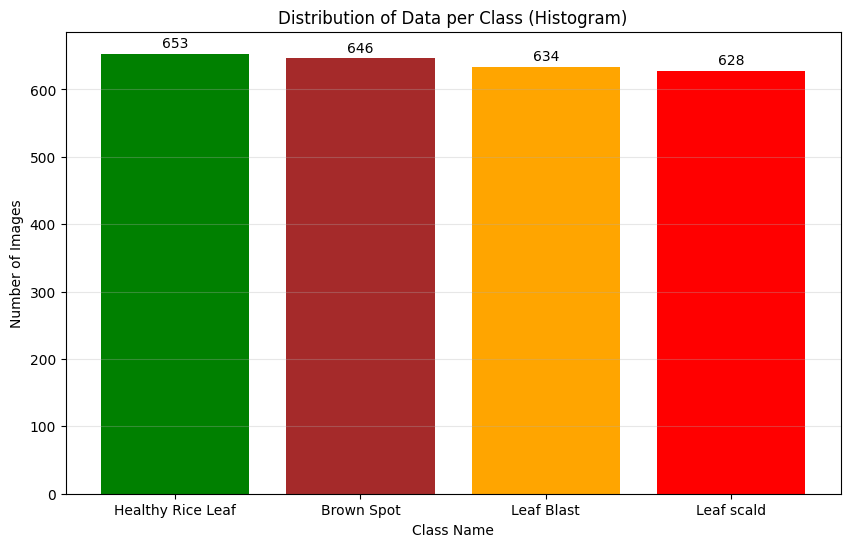

In [ ]:


#the folder direction
source_dataset_dir = os.path.join(kaggle_cnt_path, 'Rice_Leaf_AUG')

#classes : healthy +3 disease
target_classes = ['Healthy Rice Leaf', 'Brown Spot', 'Leaf Blast', 'Leaf scald']

base_dir = '/content/rice_dataset_split'

# data split
train_ratio = 0.70
val_ratio = 0.15
test_ratio = 0.15

# folders for test val train data
for split in ['train', 'val', 'test']:
    for class_name in target_classes:
        # /content/rice_dataset_split/train/Brown Spot
        dir_to_create = os.path.join(base_dir, split, class_name)
        os.makedirs(dir_to_create, exist_ok=True)

print(f"folders made in {base_dir} .")

#we want to plot histogram of num of pics, so we need a dict to save them
class_counts = {}

# copy and split
for class_name in target_classes:
    # class path
    class_source_path = os.path.join(source_dataset_dir, class_name)

    # list of all pics
    images = os.listdir(class_source_path)
    # randomly orginize the pics
    random.seed(42) # seed for a constant random
    random.shuffle(images)

    # each section count
    total_images = len(images)
    class_counts[class_name] = total_images # save to plot later

    train_split = int(train_ratio * total_images)
    val_split = int(val_ratio * total_images)

    #list split
    train_imgs = images[:train_split]
    val_imgs = images[train_split:train_split + val_split]
    test_imgs = images[train_split + val_split:]

    # file copy helper_func
    def copy_file_list(file_list, split_name):
        for img in file_list:
            src = os.path.join(class_source_path, img)
            dst = os.path.join(base_dir, split_name, class_name, img)
            shutil.copy(src, dst)

    copy_file_list(train_imgs, 'train')
    copy_file_list(val_imgs, 'val')
    copy_file_list(test_imgs, 'test')

    print(f"class {class_name}: total= {total_images} | train= {len(train_imgs)} | validation ={len(val_imgs)} | test ={len(test_imgs)}")

print("\n data split done")

# plot histogram
plt.figure(figsize=(10, 6))
bars = plt.bar(class_counts.keys(), class_counts.values(), color=['green', 'brown', 'orange', 'red'])

for bar in bars:#to see the number better , i added the num of every class on top
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 5, int(yval), ha='center', va='bottom')

plt.title('Distribution of Data per Class (Histogram)')
plt.xlabel('Class Name')
plt.ylabel('Number of Images')
plt.grid(axis='y', alpha=0.3)
plt.show()


# Q1-2. Data Preprocessing and Augmentation Strategy

In this section, we implement data augmentation to prevent overfitting and improve the model's generalization capabilities.

###  Why use "Online Augmentation" instead of expanding the dataset size?

A common misconception is that we must manually generate transformed images (e.g., rotated, flipped) and save them to the disk to increase the dataset size (e.g., making the dataset 4x larger). This approach is known as **Offline Augmentation**.

However, in this project, we utilize **Online Augmentation** (Dynamic Augmentation) provided by Keras `ImageDataGenerator`.

#### Key Differences and Advantages:

1.  **Dynamic Transformations:**
    In Online Augmentation, transformations (rotation, flipping, shifting) are applied **on-the-fly** in memory while the model is training.
    * **Epoch 1:** The model might see an image rotated by 30°.
    * **Epoch 2:** The model might see the *same* image but horizontally flipped.
    * **Epoch 3:** The model might see the *same* image shifted slightly to the left.

2.  **Infinite Diversity:**
    Unlike Offline Augmentation, which creates a fixed set of transformed images, Online Augmentation ensures that the model sees a **different variation** of the image at almost every epoch. This effectively exposes the model to a virtually infinite dataset without consuming extra disk space.

3.  **Memory Efficiency:**
    Since images are generated in batches during the training process, we do not need to store thousands of duplicate images on the disk.

> **Conclusion:** We do not need to manually multiply the dataset size. The `ImageDataGenerator` will automatically provide unique, randomized augmented batches to the model during the 30 epochs of training.



Loading Training Set:
Found 1791 images belonging to 4 classes.

Loading Validation Set:
Found 382 images belonging to 4 classes.

Loading Test Set:
Found 388 images belonging to 4 classes.


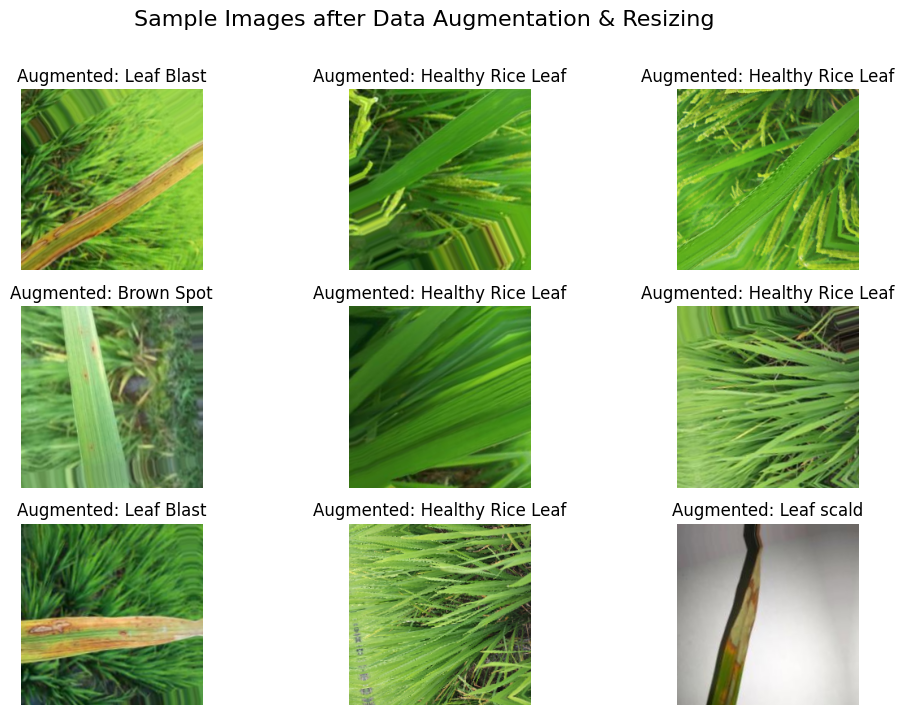

In [ ]:

base_dir = '/content/rice_dataset_split'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

#model config
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

# data generator on train

train_datagen = ImageDataGenerator(

    rescale=1./255,#getting the pixels a value between 1 and 0
    #data Augmentation , 3 methods according to the paper

    rotation_range=40,              # 1. Random Rotation
    horizontal_flip=True,           # 2. Flipping (horizental)
    vertical_flip=True,             # 2. Flipping (vertical)
    width_shift_range=0.1,         # 3. Translation (horizental)
    height_shift_range=0.1,        # 3. Translation (vertical)
    fill_mode='reflect'
     #fill_mode='constant',  #filling the empty pixels after rotation with black
     # cval=0
)

# data generator on val and test data only perform normalaizing the pixel values between 1 and 0

val_test_datagen = ImageDataGenerator(rescale=1./255)


print("\nLoading Training Set:")
train_generator = train_datagen.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

print("\nLoading Validation Set:")
validation_generator = val_test_datagen.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print("\nLoading Test Set:")
test_generator = val_test_datagen.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

#showing the produced pics
x_batch, y_batch = next(train_generator)

#6 first figs
plt.figure(figsize=(12, 8))
for i in range(9):
    plt.subplot(3, 3, i+1)
    img = x_batch[i]
    plt.imshow(img)

    # name of class finding
    label_map = {v: k for k, v in train_generator.class_indices.items()}
    label = label_map[np.argmax(y_batch[i])]

    plt.title(f"Augmented: {label}")
    plt.axis('off')

plt.suptitle("Sample Images after Data Augmentation & Resizing", fontsize=16)
plt.show()


# Q1-3. ALEXNet impelementation from scratch





In [ ]:
from tensorflow.keras import  layers, models, optimizers

#making an empty sequential model:
alex_rice_model=models.Sequential()

#1rst Conv layer:
#model.add(layers.Conv2D(filters, kernel_size, strides, activation, input_shape, padding))
alex_rice_model.add(layers.Conv2D(filters =96,kernel_size=(11,11),strides=4,activation='relu',input_shape=(224,224,3),padding='valid'))
#1rst MaxPool:
#model.add(layers.MaxPooling2D(pool_size, strides))
alex_rice_model.add(layers.MaxPooling2D(pool_size=(3,3),strides=2))
#2nd Conv layer:
alex_rice_model.add(layers.Conv2D(filters=256,kernel_size=(5,5),strides=1,activation='relu',padding='same'))
#2nd MaxPool:
alex_rice_model.add(layers.MaxPooling2D(pool_size=(3,3),strides=2))
#3rd Conv layer
alex_rice_model.add(layers.Conv2D(filters=384,kernel_size=(3,3), strides=1,activation='relu', padding='same'))
#4th Conv layer
alex_rice_model.add(layers.Conv2D(filters=384,kernel_size=(3,3), strides=1,activation='relu', padding='same'))
#5thConv layer
alex_rice_model.add(layers.Conv2D(filters=256,kernel_size=(3,3), strides=1,activation='relu', padding='same'))
#3rd MaxPool
alex_rice_model.add(layers.MaxPooling2D(pool_size=(3, 3), strides=2))


#the classifiers

alex_rice_model.add(layers.Flatten())

# FC1
alex_rice_model.add(layers.Dense(4096, activation='relu'))
alex_rice_model.add(layers.Dropout(0.5))

# FC2
alex_rice_model.add(layers.Dense(4096, activation='relu'))
alex_rice_model.add(layers.Dropout(0.5))

# Output Layer (4 classes)
alex_rice_model.add(layers.Dense(4, activation='softmax'))

# summery of model
alex_rice_model.summary()


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_23 (Conv2D)              │ (None, 54, 54, 96)     │        34,944 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 26, 26, 96)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_24 (Conv2D)              │ (None, 26, 26, 256)    │       614,656 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 12, 12, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_25 (Conv2D)              │ (None, 12, 12, 384)    │       885,120 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_26 (Conv2D)              │ (None, 12, 12, 384)    │     1,327,488 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_27 (Conv2D)              │ (None, 12, 12, 256)    │       884,992 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 5, 5, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 6400)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4096)           │    26,218,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 4096)           │    16,781,312 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_9 (Dense)                 │ (None, 4)              │        16,388 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 46,763,396 (178.39 MB)

 Trainable params: 46,763,396 (178.39 MB)

 Non-trainable params: 0 (0.00 B)

#### training the AlexNet


In [ ]:
from tensorflow.keras.optimizers import Adam

optimizer =Adam(learning_rate=0.0001)
alex_rice_model.compile(
    optimizer=optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print ("Model compiled successfully")

history = alex_rice_model.fit(
    train_generator,
    epochs=30,
    validation_data=validation_generator,
    verbose=1 # show progress bar
)

print("\n Trained.")


Model compiled successfully
Epoch 1/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 42s 646ms/step - accuracy: 0.3022 - loss: 1.3613 - val_accuracy: 0.4634 - val_loss: 1.1226
Epoch 2/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 31s 561ms/step - accuracy: 0.5084 - loss: 1.0879 - val_accuracy: 0.6099 - val_loss: 0.9167
Epoch 3/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 33s 585ms/step - accuracy: 0.5790 - loss: 0.9401 - val_accuracy: 0.6492 - val_loss: 0.8571
Epoch 4/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 32s 571ms/step - accuracy: 0.6169 - loss: 0.9118 - val_accuracy: 0.6911 - val_loss: 0.7934
Epoch 5/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 31s 557ms/step - accuracy: 0.6690 - loss: 0.7996 - val_accuracy: 0.7330 - val_loss: 0.6687
Epoch 6/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 32s 575ms/step - accuracy: 0.7238 - loss: 0.6949 - val_accuracy: 0.7696 - val_loss: 0.6238
Epoch 7/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 32s 572ms/step - accuracy: 0.7219 - loss: 0.6770 - val_accuracy: 0.7330 - val_loss: 0.6800
Epoch 8/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 32s 566ms/step - accuracy: 0.72

### plot the matrics and cofusion mat


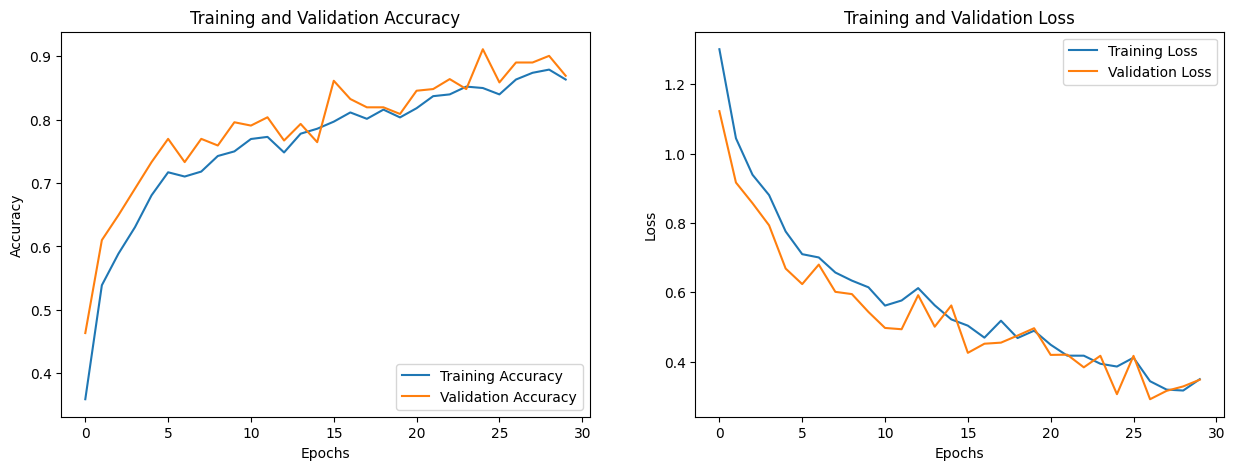


 model operation on test data
13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 230ms/step - accuracy: 0.9195 - loss: 0.2260

 Test Accuracy: 90.98%
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 273ms/step


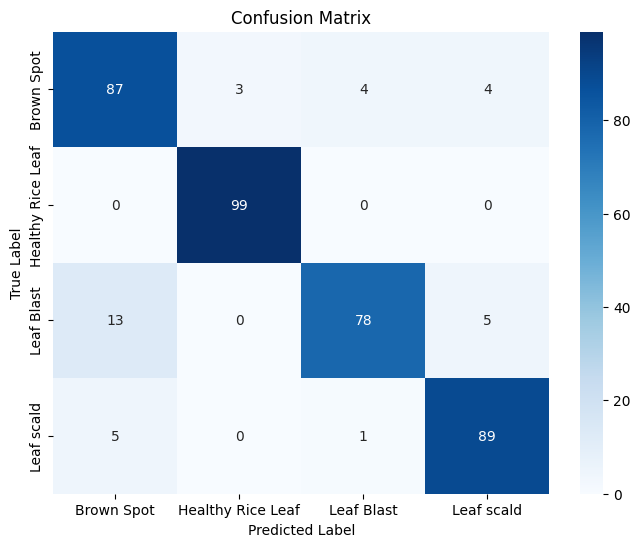


Classification Report:

                   precision    recall  f1-score   support

       Brown Spot       0.83      0.89      0.86        98
Healthy Rice Leaf       0.97      1.00      0.99        99
       Leaf Blast       0.94      0.81      0.87        96
       Leaf scald       0.91      0.94      0.92        95

         accuracy                           0.91       388
        macro avg       0.91      0.91      0.91       388
     weighted avg       0.91      0.91      0.91       388


 Detailed Metrics per Class:

Class: Brown Spot
  - Sensitivity (Recall): 0.8878
  - Specificity:          0.9379
  - Accuracy:             0.9253
------------------------------
Class: Healthy Rice Leaf
  - Sensitivity (Recall): 1.0000
  - Specificity:          0.9896
  - Accuracy:             0.9923
------------------------------
Class: Leaf Blast
  - Sensitivity (Recall): 0.8125
  - Specificity:          0.9829
  - Accuracy:             0.9407
------------------------------
Class: Leaf scald


In [ ]:


# plot Learning Curves

acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epochs_range = range(30)

plt.figure(figsize=(15, 5))

# accuracy
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

# error
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.show()

#  Test Evaluation

print("\n model operation on test data")
test_loss, test_acc = alex_rice_model.evaluate(test_generator)
print(f"\n Test Accuracy: {test_acc*100:.2f}%")

# confusion matrix and metrics

Y_pred = alex_rice_model.predict(test_generator)
y_pred = np.argmax(Y_pred, axis=1)

#real lables
y_true = test_generator.classes
class_labels = list(test_generator.class_indices.keys())

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix')
plt.show()

# Precision, Recall, F1-score
print("\nClassification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_labels))

#hand computations of Sensitivity & Specificity

# Sensitivity (Recall) = TP / (TP + FN)
# Specificity = TN / (TN + FP)

print("\n Detailed Metrics per Class:\n")
for i, label in enumerate(class_labels):
    tp = cm[i, i]
    fn = np.sum(cm[i, :]) - tp
    fp = np.sum(cm[:, i]) - tp
    tn = np.sum(cm) - (tp + fp + fn)

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)

    print(f"Class: {label}")
    print(f"  - Sensitivity (Recall): {sensitivity:.4f}")
    print(f"  - Specificity:          {specificity:.4f}")
    print(f"  - Accuracy:             {accuracy:.4f}")
    print("-" * 30)


# Q1-4. INC-VGGN model impelementation






In [ ]:
from tensorflow.keras.applications.vgg19 import preprocess_input
from tensorflow.keras.applications import VGG19
from tensorflow.keras.optimizers import SGD
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns


#### data preprocessing and augmentation


In [ ]:

base_dir = '/content/rice_dataset_split'
train_dir = os.path.join(base_dir, 'train')
val_dir = os.path.join(base_dir, 'val')
test_dir = os.path.join(base_dir, 'test')

# model config
IMG_SIZE = (224, 224)
BATCH_SIZE = 32 # every moment , we import 32 RGB pics to the grafic card

train_datagen_vgg= ImageDataGenerator(
    preprocessing_function=preprocess_input,

    #same as before
    rotation_range=40,              # 1. Random Rotation
    horizontal_flip=True,           # 2. Flipping (horizental)
    vertical_flip=True,             # 2. Flipping (vertical)
    width_shift_range=0.1,          # 3. Translation (horizental)
    height_shift_range=0.1,         # 3. Translation (vertical)

    fill_mode='reflect'
    #fill_mode='constant',  #filling the empty pixels after rotation with black
    #cval=0
)


val_test_datagen_vgg = ImageDataGenerator(preprocessing_function=preprocess_input)

#loading data generator

print("VGG: Loading Training Set:")
train_generator_vgg= train_datagen_vgg.flow_from_directory(
    train_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=True
)

print("\nVGG:Loading Validation Set:")
validation_generator_vgg= val_test_datagen_vgg.flow_from_directory(
    val_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)

print("\nVGG:Loading Test Set:")
test_generator_vgg= val_test_datagen_vgg.flow_from_directory(
    test_dir,
    target_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    class_mode='categorical',
    shuffle=False
)


VGG: Loading Training Set:
Found 1791 images belonging to 4 classes.

VGG:Loading Validation Set:
Found 382 images belonging to 4 classes.

VGG:Loading Test Set:
Found 388 images belonging to 4 classes.


### Impelementing VGG , inception, Swish


In [ ]:
#define the Swish activation function:
def Swish(x):
  return x*tf.keras.activations.sigmoid(x)

#define inception module
def Inception(x,fltr1,fltr3,fltr3_red,fltr5,fltr5_red, fltr_pool):
  p1_1x1=layers.Conv2D(fltr1,(1,1),padding='same', activation ='relu')(x)
  p2_3x3=layers.Conv2D(fltr3_red,(1,1),padding='same',activation='relu')(x)
  p2_3x3=layers.Conv2D(fltr3,(3,3),padding='same',activation='relu')(p2_3x3)
  p3_5x5=layers.Conv2D(fltr5_red,(5,5),padding='same',activation='relu')(x)
  p3_5x5=layers.Conv2D(fltr5,(5,5),padding='same',activation='relu')(p3_5x5)
  p4_pool=layers.MaxPooling2D((3,3),strides=(1,1),padding='same')(x)
  p4_pool=layers.Conv2D(fltr_pool,(1,1),padding='same',activation='relu')(p4_pool)
  return layers.concatenate([p1_1x1,p2_3x3,p3_5x5,p4_pool],axis=-1)

#The VGG

orig_vgg=VGG19(weights='imagenet',include_top=False,input_shape=(224,224,3))
orig_vgg.trainable=False

vgg_cut_point=orig_vgg.get_layer('block4_pool').output

x=layers.Conv2D(512,(3,3),padding='same')(vgg_cut_point)
x = layers.BatchNormalization()(x)
x = layers.Activation(Swish, name='Swish')(x)

x= Inception(x,fltr1=64 , fltr3=128 , fltr3_red=96 , fltr5=32 , fltr5_red=16 , fltr_pool=32 )
x= Inception(x,fltr1=64 , fltr3=128 , fltr3_red=96 , fltr5=32 , fltr5_red=16 , fltr_pool=32)

x = layers.GlobalAveragePooling2D()(x)

#x = layers.Dropout(0.05)(x)

# output layer
output = layers.Dense(4, activation='softmax')(x)

INC_VGG = models.Model(inputs=orig_vgg.input, outputs=output)
optimizer=SGD(learning_rate=0.001, momentum=0.9)

INC_VGG.compile(
    optimizer=optimizer,
    loss='categorical_crossentropy',
    metrics=['accuracy']
)

print ('\n INC_VGG model compiled')
# summery
INC_VGG.summary()




 INC_VGG model compiled


Model: "functional_43"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_4       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv1        │ (None, 224, 224,  │      1,792 │ input_layer_4[0]… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_conv2        │ (None, 224, 224,  │     36,928 │ block1_conv1[0][… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1_pool         │ (None, 112, 112,  │          0 │ block1_conv2[0][… │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv1        │ (None, 112, 112,  │     73,856 │ block1_pool[0][0] │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_conv2        │ (None, 112, 112,  │    147,584 │ block2_conv1[0][… │
│ (Conv2D)            │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block2_pool         │ (None, 56, 56,    │          0 │ block2_conv2[0][… │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv1        │ (None, 56, 56,    │    295,168 │ block2_pool[0][0] │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv2        │ (None, 56, 56,    │    590,080 │ block3_conv1[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv3        │ (None, 56, 56,    │    590,080 │ block3_conv2[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_conv4        │ (None, 56, 56,    │    590,080 │ block3_conv3[0][… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block3_pool         │ (None, 28, 28,    │          0 │ block3_conv4[0][… │
│ (MaxPooling2D)      │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv1        │ (None, 28, 28,    │  1,180,160 │ block3_pool[0][0] │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv2        │ (None, 28, 28,    │  2,359,808 │ block4_conv1[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv3        │ (None, 28, 28,    │  2,359,808 │ block4_conv2[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_conv4        │ (None, 28, 28,    │  2,359,808 │ block4_conv3[0][… │
│ (Conv2D)            │ 512)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block4_pool         │ (None, 14, 14,    │          0 │ block4_conv4[0][

 Total params: 13,650,212 (52.07 MB)

 Trainable params: 3,064,036 (11.69 MB)

 Non-trainable params: 10,586,176 (40.38 MB)

#### training the INC-VGG


In [ ]:

print ('\n Start of training INC_VGG :')

INC_VGG_history=INC_VGG.fit(
    train_generator_vgg,
    epochs=30,
    validation_data=validation_generator_vgg,
    verbose=1
)
print ('\n End of training INC_VGG .')



 Start of training INC_VGG :


/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 48s 756ms/step - accuracy: 0.3030 - loss: 1.4026 - val_accuracy: 0.4267 - val_loss: 1.2040
Epoch 2/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 36s 646ms/step - accuracy: 0.5437 - loss: 1.1734 - val_accuracy: 0.6126 - val_loss: 0.9485
Epoch 3/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 37s 659ms/step - accuracy: 0.6117 - loss: 0.9415 - val_accuracy: 0.6257 - val_loss: 0.9176
Epoch 4/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 36s 649ms/step - accuracy: 0.6876 - loss: 0.7838 - val_accuracy: 0.7723 - val_loss: 0.6381
Epoch 5/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 36s 648ms/step - accuracy: 0.7234 - loss: 0.6674 - val_accuracy: 0.6728 - val_loss: 0.7045
Epoch 6/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 36s 650ms/step - accuracy: 0.7833 - loss: 0.5515 - val_accuracy: 0.8089 - val_loss: 0.4768
Epoch 7/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 36s 648ms/step - accuracy: 0.8119 - loss: 0.4765 - val_accuracy: 0.8246 - val_loss: 0.4528
Epoch 8/30
56/56 ━━━━━━━━━━━━━━━━━━━━ 37s 668ms/step - accuracy: 0.8309 - loss: 0.4409 - val_accu

#### plot the metrics and cofusion mat


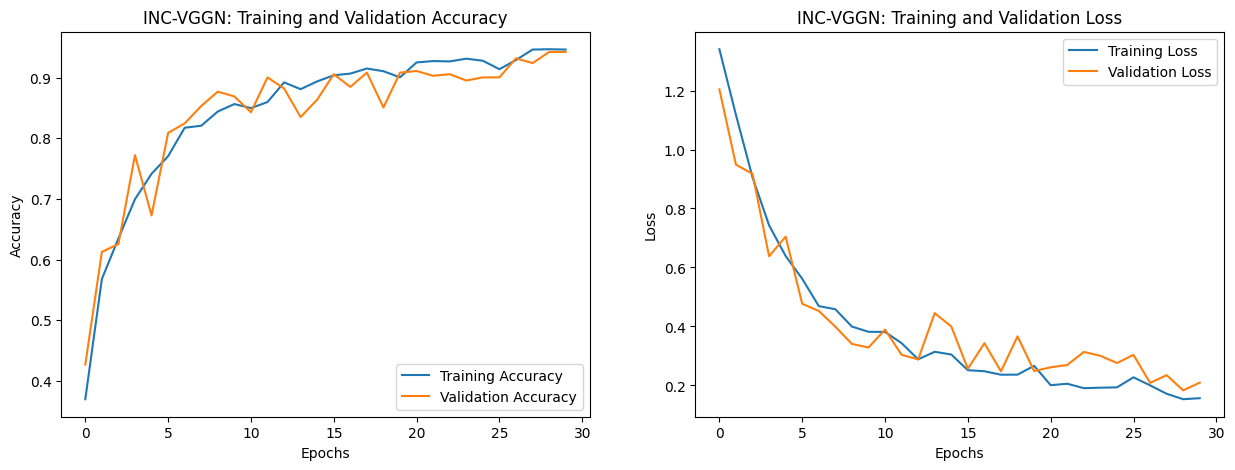


Testing INC-VGGN on test data:
13/13 ━━━━━━━━━━━━━━━━━━━━ 5s 379ms/step - accuracy: 0.9812 - loss: 0.0685

 INC-VGGN Test Accuracy: 96.13%
13/13 ━━━━━━━━━━━━━━━━━━━━ 6s 371ms/step


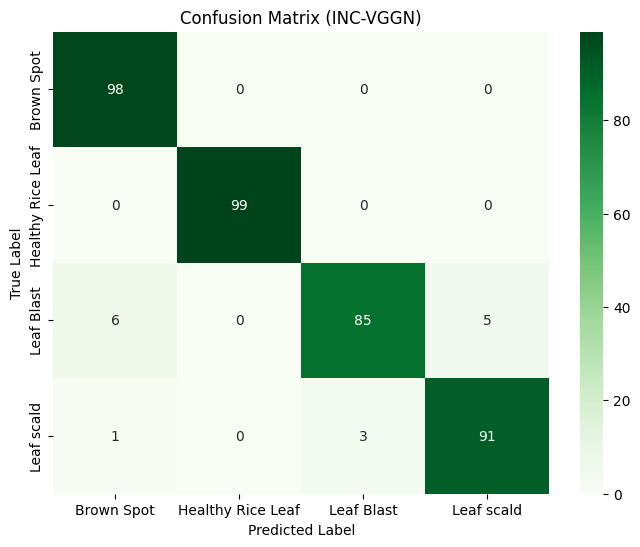


 Classification Report:

                   precision    recall  f1-score   support

       Brown Spot       0.93      1.00      0.97        98
Healthy Rice Leaf       1.00      1.00      1.00        99
       Leaf Blast       0.97      0.89      0.92        96
       Leaf scald       0.95      0.96      0.95        95

         accuracy                           0.96       388
        macro avg       0.96      0.96      0.96       388
     weighted avg       0.96      0.96      0.96       388


 Detailed Metrics per Class (INC-VGGN):

Class: Brown Spot
  - Sensitivity (Recall): 1.0000
  - Specificity:          0.9759
  - Accuracy:             0.9820
------------------------------
Class: Healthy Rice Leaf
  - Sensitivity (Recall): 1.0000
  - Specificity:          1.0000
  - Accuracy:             1.0000
------------------------------
Class: Leaf Blast
  - Sensitivity (Recall): 0.8854
  - Specificity:          0.9897
  - Accuracy:             0.9639
------------------------------
Class:

In [ ]:

#Learning Curves

acc = INC_VGG_history.history['accuracy']
val_acc = INC_VGG_history.history['val_accuracy']
loss = INC_VGG_history.history['loss']
val_loss = INC_VGG_history.history['val_loss']
epochs_range = range(len(acc))

plt.figure(figsize=(15, 5))

# accuracy plot
plt.subplot(1, 2, 1)
plt.plot(epochs_range, acc, label='Training Accuracy')
plt.plot(epochs_range, val_acc, label='Validation Accuracy')
plt.legend(loc='lower right')
plt.title('INC-VGGN: Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')

# error plot
plt.subplot(1, 2, 2)
plt.plot(epochs_range, loss, label='Training Loss')
plt.plot(epochs_range, val_loss, label='Validation Loss')
plt.legend(loc='upper right')
plt.title('INC-VGGN: Training and Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')

plt.show()

# Test Evaluation

print("\nTesting INC-VGGN on test data:")
test_loss, test_acc = INC_VGG.evaluate(test_generator_vgg)
print(f"\n INC-VGGN Test Accuracy: {test_acc*100:.2f}%")

#confusion matrix and report

# prediction on all test datas
Y_pred = INC_VGG.predict(test_generator_vgg)
y_pred = np.argmax(Y_pred, axis=1)

# real labels
y_true = test_generator_vgg.classes
class_labels = list(test_generator_vgg.class_indices.keys())

# draw Heatmap
cm = confusion_matrix(y_true, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', xticklabels=class_labels, yticklabels=class_labels)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix (INC-VGGN)')
plt.show()

print("\n Classification Report:\n")
print(classification_report(y_true, y_pred, target_names=class_labels))


# hand calculation of Sensitivity & Specificity

print("\n Detailed Metrics per Class (INC-VGGN):\n")
for i, label in enumerate(class_labels):
    tp = cm[i, i]
    fn = np.sum(cm[i, :]) - tp
    fp = np.sum(cm[:, i]) - tp
    tn = np.sum(cm) - (tp + fp + fn)

    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    accuracy = (tp + tn) / (tp + tn + fp + fn)

    print(f"Class: {label}")
    print(f"  - Sensitivity (Recall): {sensitivity:.4f}")
    print(f"  - Specificity:          {specificity:.4f}")
    print(f"  - Accuracy:             {accuracy:.4f}")
    print("-" * 30)
